первые 5 строк:
x=+0.2740  x*x=0.0751  noise=+0.0161  y=0.0911
x=-0.0611  x*x=0.0037  noise=-0.0099  y=-0.0061
x=+0.3586  x*x=0.1286  noise=-0.0001  y=0.1285
x=+0.1974  x*x=0.0390  noise=-0.0041  y=0.0349
x=-0.4058  x*x=0.1647  noise=+0.0084  y=0.1731
linear : 0.0053 0.0798 0.00558
tree d2: 0.00177
tree d4: 0.00062


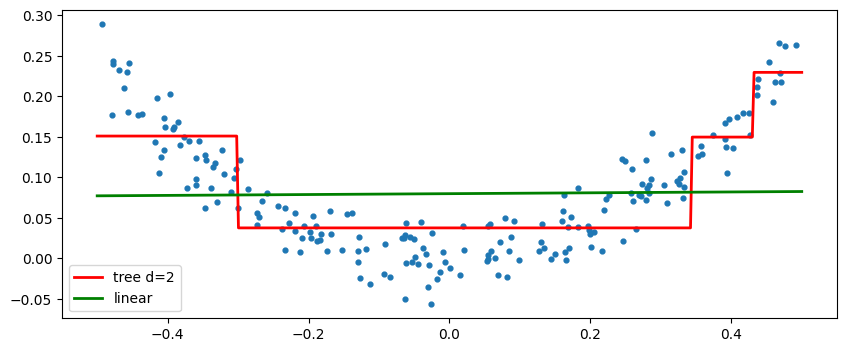

In [14]:
# Параболы и всякая фигня что это такое вообще

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

rng = np.random.default_rng(seed=42)

X = rng.random((200, 1)) - 0.5
noise = 0.025 * rng.standard_normal((200,1))
y = X**2 + noise # идеальная парабола + грязь

print("первые 5 строк:")
for i in range(5):
    print(f"x={X[i][0]:+.4f}  x*x={X[i][0]**2:.4f}  noise={noise[i][0]:+.4f}  y={y[i][0]:.4f}")

def mse(model):
    pred = model.predict(X).reshape(-1)
    return round(((y.reshape(-1) - pred)**2).mean(), 5)

lin  = LinearRegression().fit(X, y)
t2   = DecisionTreeRegressor(max_depth=2, random_state=42).fit(X, y)
t4   = DecisionTreeRegressor(max_depth=4, random_state=42).fit(X, y)

print("linear :", round(lin.coef_[0][0], 4), round(lin.intercept_[0], 4), mse(lin))
print("tree d2:", mse(t2))
print("tree d4:", mse(t4))

plt.figure(figsize=(10, 4))
plt.scatter(X, y, s=12)
xs = np.linspace(-0.5, 0.5, 400).reshape(-1, 1)
plt.plot(xs, t2.predict(xs), "r-", lw=2, label="tree d=2")
plt.plot(xs, lin.predict(xs), "g-", lw=2, label="linear")
plt.legend(); plt.show()

In [12]:
default = y[0:3]
reshaped = y.reshape(-1)[0:3]
print(default,"\n")
print(reshaped, "\n")
print(default.shape)
print(reshaped.shape)


[[ 0.09113509]
 [-0.00612928]
 [ 0.12846442]] 

[ 0.09113509 -0.00612928  0.12846442] 

(3, 1)
(3,)
